# 4b — The live 2026-27 Most Improved race

**In brief**
- **Question:** Who leads the live 2026-27 Most Improved race, and how far should we trust it at this point of the season?
- **Answer:** The leader changes as games are played (see A for the latest board). Early on, treat the board as a rough shortlist: at about three weeks in, the eventual winner was in our top 7 in 9 of 15 past seasons (notebook 4, section 4A). It becomes a real ranking from about the All-Star break.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D22–D24, D30, D32, D38–D42.
- **Where it fits:** The live model. Update it with `./scripts/update_mip_race.sh`. Its backtests (how far to trust the board at each point of the season; the last five seasons) are in [notebook 4](4_mip_race.ipynb), so that each update only adds the new days.
- **Dated:** the live findings (A–C) are updated by hand after each run of the race; latest 17 November 2026 (day 28 after opening night).
- **Days** are counted after opening night everywhere in the project: opening night is day 0, so day 19 is about three weeks in. Only complete nights are used: a night's games count from 4 a.m. US Eastern the next morning, so a run during a game night never saves a half-played day.

> **The model is frozen until the end of 2026-27 (D44, 12 November):** inputs and settings stay as of D42, bug fixes only, so this season is a genuine out-of-sample test. The turning point is still re-chosen daily until the All-Star break (D32), as set before the freeze.

**Re-run this notebook whenever you want an update.** It downloads the newest game logs, adds the new days and redraws the charts.

**In detail.** Who leads the 2026-27 Most Improved Player (MIP) race so far, and how much should we believe it at this point of the season?

**Decisions**
- **Same comparison as notebook 10:** this season's per-game numbers so far against each player's baseline season (most recent season with at least 33% of the games).
- **A model for each point of the season.** The model is trained on past seasons cut at the **same number of days after opening night**, so it has learned how much a few days of games say about the eventual winner. Season-long stats (usage, start rate, defensive rating) are left out, as in notebook 10's mid-season race.
- **Inputs:** changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team win % change; age; second-year flag. Penalty λ = 3.
- **Candidates:** at least one previous NBA season, a baseline season, and at least half of his team's games so far. Previous winners are included.
- **Established players:** the baseline season's **game score** counts for a player up to a turning point and against him above it (decision D41, 12 November; it was on points until then, D27). **The data chooses the turning point** (none, or game score 12.5, 14, 15.5, 17 or 18.5: the same percentiles of candidates as 16–24 points), re-chosen every day from past seasons only by season-grouped cross-validation, the same method as notebook 15. It is **frozen at the All-Star break**, so the leaderboard doesn't jump late in the race (decision D32, 30 October). With the D42 inputs it has moved between none, 14 and 15.5 (15.5 today).
- **Already an All-Star** (from 9 November, decision D38): 1 if the player was an All-Star in any earlier season. It counts against him; no winner since 2000-01 had been one (notebook 17).
- **Already clearly a star** (from 12 November, decision D42): a baseline game score of 16 or more, and last season in our star tier (top 10% by star score, notebook 05). Both count against a player: stars who improve get MVP votes, not Most Improved (notebook 21).
- **Back from a lost season** (from 10 November, decision D39): 1 if the baseline season is older than last season, because last season was lost or injury-shortened. It counts against him; no winner since 2000-01 was in that position (notebook 18).
- **Points per game** appear in the tables and charts for readability only. The model uses every input listed above (B4, Phase B).
- **Age** is rolled forward from each player's latest season in our table, so players who missed 2025-26 (Tyrese Haliburton, Damian Lillard) still get one.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguegamelog
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
LIVE, LIVE_START, L2 = "2026-27", 2026, 3.0
from functools import lru_cache
from unicorn.gamelogs import all_star_breaks
from unicorn.mip_history import TURN_CHOICES, choose_turning_point, with_turn
from unicorn.preseason import TURNING_POINT       # the preseason model's turning point (notebook 11), used in B
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.hot_start import add_stale
SEL = load_selections()
from unicorn.mip_eval import LIVE_LEVEL, LIVE_TURN_CHOICES   # the turning point is on the baseline season's game score (D41)
from unicorn.established import STAR_INPUTS   # baseline game score 16+, baseline season in the star tier (D42)
EARLY_BASE = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR + [LIVE_LEVEL, "prior_allstar", "stale"] + STAR_INPUTS   # D38, D39, D42
EARLY = EARLY_BASE + ["over_turn"]                # over_turn = baseline game score above the turning point the data chose (D32, D41)

import unicorn.live_race as LR
games = LR.live_games(refresh=True)                # downloads the newest 2026-27 games
# complete nights only: a night counts from 4 a.m. US Eastern the next morning, so a run during a game night never uses or saves a half-played day
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
LAST_COMPLETE = pd.Timestamp((datetime.now(ZoneInfo("America/New_York")) - timedelta(hours=4)).date() - timedelta(days=1))
unfinished = (games["season"] == LIVE) & (games["game_date"] > LAST_COMPLETE)
if unfinished.any():
    print(f"left out until the night is over: {games.loc[unfinished, 'game_id'].nunique()} games on {games.loc[unfinished, 'game_date'].min():%d %b}")
games = games[~unfinished]
live_games = games[games["season"] == LIVE]
DAY_NOW = int(live_games["day"].max())
team_games = live_games.groupby("team_id")["game_id"].nunique()
asb = all_star_breaks(live_games).iloc[0]
FREEZE_DAY = int((asb["last_game_before"] - live_games["game_date"].min()).days) if asb["gap_days"] >= 4 else None   # last day before the All-Star break
print(f"{LIVE}: {live_games['game_id'].nunique()} games through {live_games['game_date'].max():%d %b %Y} "
      f"(day {DAY_NOW} after opening night); teams have played {team_games.min()}–{team_games.max()} games")
print("All-Star break:", "not reached yet" if FREEZE_DAY is None else f"last games on day {FREEZE_DAY}; turning point frozen from then on")
print("how far to trust the board at this point of the season: notebook 4, section 4A")


2026-27: 210 games through 17 Nov 2026 (day 28 after opening night); teams have played 12–15 games
All-Star break: not reached yet
how far to trust the board at this point of the season: notebook 4, section 4A


In [2]:
# player table with a 2026-27 row (age and experience rolled forward); candidates on any day (src/unicorn/live_race.py)
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
ps_live = LR.player_table_with_live_season(ps)

def race(day):
    """Eligible candidates in every season, using only games up to `day` days after that season's opener.
    Previous winners included; already an All-Star (D38) and back from a lost season (D39) added."""
    return LR.race(games, ps_live, day, SEL)

def pick_turn(train):
    """Turning point chosen by season-grouped cross-validation on past seasons only; None = no turning point."""
    return choose_turning_point(train, EARLY_BASE, LIVE_LEVEL, grid=LIVE_TURN_CHOICES)

@lru_cache(maxsize=None)
def turn_for_day(day):
    """The live race's turning point on a given day: re-chosen every day until the All-Star break, then frozen (D32)."""
    d = day if FREEZE_DAY is None else min(day, FREEZE_DAY)
    c = race(d)
    return pick_turn(c[c["season"] != LIVE])

def turn_label(k):
    return "none" if k is None else f"game score {k:g}"

now = race(DAY_NOW)
K_NOW = turn_for_day(DAY_NOW)
now = with_turn(now, LIVE_LEVEL, K_NOW)
print("turning point today:", turn_label(K_NOW))
print("live candidates:", (now["season"] == LIVE).sum(), "| missing age:", now.loc[now["season"] == LIVE, "age"].isna().sum())

turning point today: game score 15.5
live candidates: 297 | missing age: 0


## A — The race today

In [3]:
hist, T = now[now["season"] != LIVE], now[now["season"] == LIVE].copy()
model = ChoiceModel(EARLY, L2).fit(hist)
T["chance"] = model.predict_proba(T)
T = T.sort_values("chance", ascending=False).reset_index(drop=True)
T["rank"] = np.arange(1, len(T) + 1)

NICE = {"ppg_delta": "points", "rpg_delta": "rebounds", "apg_delta": "assists", "spg_delta": "steals", "bpg_delta": "blocks",
        "mpg_delta": "minutes", "game_score_delta": "game score", "ts_delta": "shooting efficiency", "ppg_rel": "points (relative)",
        "game_score_rel": "game score (relative)", "team_win_delta": "team winning more", "age": "age", "second_year": "second-year discount",
        "base_ppg": "baseline scoring", "base_game_score": "baseline game score", "over_turn": f"baseline above the turning point ({turn_label(K_NOW)})", "prior_allstar": "already an All-Star", "stale": "back from a lost season", "elite_level": "baseline game score 16+", "base_star_tier": "star tier last season"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=EARLY)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)
T["why"] = [" + ".join(contrib.drop(columns=["second-year discount", NICE["over_turn"], "already an All-Star", "back from a lost season", "baseline game score 16+", "star tier last season"]).loc[i].nlargest(2).index) for i in T.index]   # the discount is never a reason to pick someone
print("turning point:", turn_label(K_NOW))
EARLY_DAY, EARLY_HIGH = 45, 0.25      # D40: big early favourites have been too sure (notebook 20)
if DAY_NOW < EARLY_DAY and T["chance"].max() > EARLY_HIGH:
    print(f"NOTE (D40): {T.loc[0, 'player_name']} is above 25% before day {EARLY_DAY}. Since 2000-01, 19 early favourites given 25%+ "
          f"averaged about 40% and only 3 won (about 1 in 6). Read this as 'clear early favourite', not as the number.")
else:
    print(f"calibration (D40): no early chance above {EARLY_HIGH:.0%} today; chances are honest on the whole (notebook 20)")
print("weights:", model.coefficients().rename(NICE).round(2).sort_values(ascending=False).to_dict())
cols = {"rank": "rank", "player_name": "player", "team": "team", "chance": "chance", "games": "games", "ppg": "points", "base_ppg": "points last season",
        "game_score": "game score", "base_game_score": "game score last season", "mpg": "minutes", "base_mpg": "minutes last season", "age": "age", "why": "main reasons"}
T.head(10)[list(cols)].rename(columns=cols).style.format({"chance": "{:.1%}"}, precision=1).hide(axis="index")

turning point: game score 15.5
calibration (D40): no early chance above 25% today; chances are honest on the whole (notebook 20)
weights: {'points': 0.86, 'baseline game score': 0.86, 'game score': 0.62, 'points (relative)': 0.32, 'assists': 0.22, 'blocks': 0.19, 'rebounds': 0.16, 'game score (relative)': 0.1, 'steals': 0.08, 'team winning more': 0.04, 'shooting efficiency': 0.02, 'baseline above the turning point (game score 15.5)': -0.21, 'star tier last season': -0.29, 'back from a lost season': -0.3, 'baseline game score 16+': -0.36, 'already an All-Star': -0.44, 'minutes': -0.53, 'age': -0.55, 'second-year discount': -0.68}


rank,player,team,chance,games,points,points last season,game score,game score last season,minutes,minutes last season,age,main reasons
1,Davion Mitchell,MIA,15.7%,14,16.7,9.3,16.0,9.4,35.5,28.6,28.4,points + game score
2,Ty Jerome,MEM,10.0%,11,25.4,12.5,18.5,10.7,30.6,19.9,29.6,points + game score
3,Franz Wagner,ORL,9.4%,13,24.2,20.6,18.2,15.6,36.8,30.0,25.4,points + assists
4,Terrence Shannon Jr,MIN,4.4%,12,12.9,5.6,9.5,3.8,22.8,12.4,26.5,points + game score
5,Anthony Black,ORL,3.3%,10,16.7,15.0,13.9,11.1,32.3,29.9,23.0,game score + points
6,Ajay Mitchell,OKC,2.9%,12,18.1,13.6,13.6,11.2,27.2,25.8,24.6,points + game score
7,Ayo Dosunmu,MIN,1.9%,15,18.6,14.8,14.1,12.1,31.6,27.3,27.0,points + game score
8,Jaden McDaniels,MIN,1.9%,15,17.1,14.8,14.0,11.5,33.5,31.7,26.3,points + game score
9,Jalen Smith,CHI,1.8%,12,13.3,10.2,12.7,8.9,24.9,20.6,26.9,points + game score
10,Brandin Podziemski,GSW,1.8%,12,16.3,13.8,13.4,11.5,32.2,28.5,23.9,points + game score


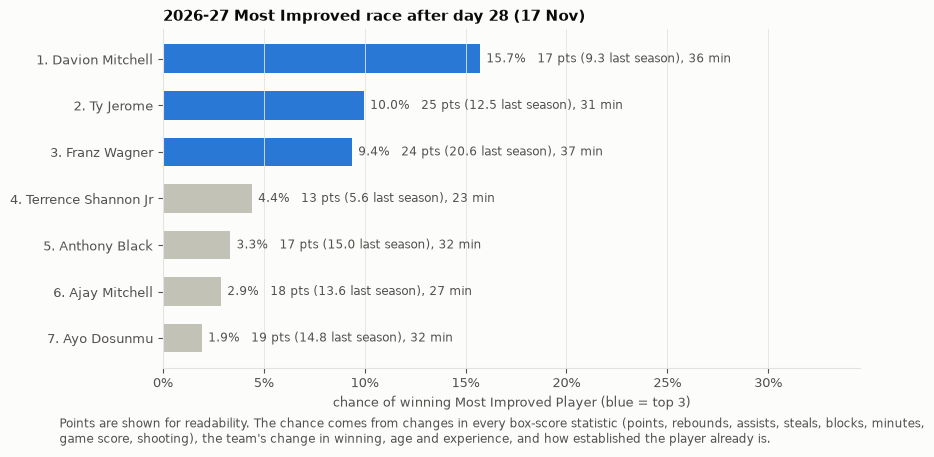

In [4]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + top["chance"].max() * 0.02, yi, f"{r['chance']:.1%}   {r['ppg']:.0f} pts ({r['base_ppg']:.1f} last season), {r['mpg']:.0f} min",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.2); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = top 3)")
ax.set_title(f"{LIVE} Most Improved race after day {DAY_NOW} ({live_games['game_date'].max():%d %b})", loc="left")
fig.text(0.01, 0.0, "Points are shown for readability. The chance comes from changes in every box-score statistic (points, rebounds, assists, steals, blocks, minutes, game score, shooting), the team's change in winning, age and experience, and how established the player already is.", ha="left", va="top", fontsize=8.5, color=INK2, wrap=True)   # B4: points are for readability
fig.savefig(FIG_DIR / "12_race_today.png", dpi=150, bbox_inches="tight")

In [5]:
# how our preseason top 7 has started: notebook 11's final list (complete preseason; model as of 10 November, with D38 and D39)
PRESEASON_TOP7 = ["Rui Hachimura", "Brandon Miller", "Cooper Flagg", "Tristan da Silva", "Sandro Mamukelashvili", "Zaccharie Risacher", "Naz Reid"]
rows = []
for i, name in enumerate(PRESEASON_TOP7, 1):
    r = T[T["player_name"] == name]
    played = live_games[live_games["player_name"] == name]
    rows.append({"preseason rank": i, "player": name, "games": len(played),
                 "points": played["pts"].mean() if len(played) else np.nan,
                 "points last season": r["base_ppg"].iloc[0] if len(r) else np.nan,
                 "race rank now": int(r["rank"].iloc[0]) if len(r) else None, "chance now": f"{r['chance'].iloc[0]:.1%}" if len(r) else "not yet a candidate"})
pd.DataFrame(rows).set_index("preseason rank").round(1)

,player,games,points,points last season,race rank now,chance now
preseason rank,,,,,,
1,Rui Hachimura,11,13.3,11.5,50,0.4%
2,Brandon Miller,12,19.9,20.2,72,0.2%
3,Cooper Flagg,13,23.5,21.0,36,0.5%
4,Tristan da Silva,11,14.6,9.9,18,1.0%
5,Sandro Mamukelashvili,15,9.9,11.2,132,0.1%
6,Zaccharie Risacher,14,8.8,9.6,49,0.4%
7,Naz Reid,14,17.6,13.6,28,0.6%


### A findings (17 November, day 28 after opening night; teams have played 12–15 games)

- **Davion Mitchell leads (15.7%)** and has led since day 25 (14 November). He's scoring 16.7 points a game, against 9.3 in his baseline season (2024-25), with 7 more minutes a game.
- **Ty Jerome is 2nd (10.0%).** He led on every day from day 1 to day 23 except day 9, but has played only one game since day 22 (11 games in all). He's scoring 25.4 points a game, against 12.5. Coming back from an injury-shortened 2025-26 (D39) and his age hold his chance down.
- **The chasing group:** Franz Wagner (9.4%; 24.2 points against 20.6; he led on day 24), Terrence Shannon Jr (4.4%; 12.9 against 5.6, with 10 more minutes), Anthony Black (3.3%), Ajay Mitchell (2.9%) and Ayo Dosunmu (1.9%). Brandin Podziemski has dropped to 10th and Kyshawn George to 12th.
- **The established stars stay back.** Cooper Flagg is 36th (0.5%) and Victor Wembanyama 38th (0.5%): the established-star inputs count against them (D42). Alperen Sengun is 30th and Scottie Barnes 125th.
- **Previous winners are in the pool:** Nickeil Alexander-Walker is 43rd, because he hasn't improved on his winning season (see [notebook 3, case 3A](3_mip_investigations.ipynb)).
- **Notebook 11's preseason top 7 is still slow.** Tristan da Silva (18th) is the closest; Naz Reid is 28th, Cooper Flagg 36th, Zaccharie Risacher 49th, Rui Hachimura 50th, Brandon Miller 72nd and Sandro Mamukelashvili 132nd.
- **What the model rewards at day 28:**
  - **For:** a points jump (+0.86 per SD), the baseline season's game score up to the turning point (+0.86), and jumps in game score (+0.62), points relative to the baseline (+0.32) and assists (+0.22).
  - **Against:** second-year players (−0.68), age (−0.55), a minutes jump without more production (−0.53), already an All-Star (−0.44), a baseline game score of 16+ (−0.36), coming back from a lost season (−0.30), last season in the star tier (−0.29) and a baseline game score above the turning point (−0.21).
- **The turning point** has been game score 15.5 every day since day 22.
- **No big early favourite:** no chance is above 25%, so the D40 note does not apply.

**Re-run** this notebook at any time (or `./scripts/update_mip_race.sh`); the first cell downloads the latest games.


## B — Three snapshots of the 2026-27 race, and the reasons behind each pick

Who did we think would rise most, at three points in time?

1. **End of 2025-26:** last season only (level, role, momentum, age). The 11 model without preseason inputs.
2. **End of preseason:** the 11 model, now with the **full** preseason (11 itself was run on preseason games through 12 October).
3. **Today:** the live race from A.

All three snapshots use the same rules: no exclusions. The two preseason snapshots use notebook 11's turning point (20 points, D27); today's uses the live race's (game score, D41).

**Reasons** are shown two ways: the inputs that pushed each player up most in each model, and plain facts about his situation (role, minutes, points, rebounds, opportunity). The facts are descriptive; "opportunity" (minutes that left his team over the summer) is **not** a model input.

In [6]:
# SNAPSHOTS
from unicorn.preseason import ESTABLISHED, RETURNING, LAST_SEASON_LEAN, MOMENTUM, PROFILE, TURN, USED, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame

past_games = games[games["season"] != LIVE]
pre = load_preseason(regular=games, refresh_latest=False)           # the complete 2026-27 preseason, cached (it ended 16 October)
pre_now = pre[pre["season"] == LIVE]
print(f"{LIVE} preseason: {pre_now['game_id'].nunique()} games, {pre_now['game_date'].min():%d %b} → {pre_now['game_date'].max():%d %b}")

F = add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, past_games, ps), MIP_WINNERS)), pre, games)   # no exclusions
F = add_stale(add_prior_allstar(F, SEL))
FH = F[F["season"] != LIVE].reset_index(drop=True)
FT = F[F["season"] == LIVE].reset_index(drop=True)

NICE_PRE = {"mpg_last": "minutes last season", "ppg_last": "points last season", "usg_last": "usage last season",
            "team_win_pct_last": "team's wins last season", "age": "age", "second_year": "second-year discount", "new_team": "new team",
            "momentum_game_score": "improved last season", "late_surge_last": "strong finish last season",
            "pre_game_score_change": "preseason production per 36", "pre_volume_change": "preseason shot volume per 36",
            "pre_ts_change": "preseason shooting", "ppg_over_turn": f"points above {TURNING_POINT} last season",
            "star_left": "a 20-point scorer left (not replaced)", "prior_allstar": "already an All-Star", "stale": "back from a lost season"}

def snapshot(train, test, features, nice):
    m = ChoiceModel(features, L2).fit(train)
    out = test[["player_id", "player_name"]].copy()
    out["chance"] = m.predict_proba(test)
    out["rank"] = out["chance"].rank(ascending=False, method="first").astype(int)
    Z = pd.DataFrame(m._design(test), index=test.index, columns=features)
    c = ((Z - Z.mean()) * m.coef_).rename(columns=nice)
    out["model reasons"] = [", ".join(c.drop(columns=["second-year discount", f"points above {TURNING_POINT} last season", "already an All-Star", "back from a lost season"]).loc[i].nlargest(2).index) for i in test.index]
    return out.set_index("player_id")

S1 = snapshot(FH, FT, LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN + ESTABLISHED + RETURNING, NICE_PRE)
S2 = snapshot(FH, FT, USED, NICE_PRE)
S3 = T.set_index("player_id")[["player_name", "chance", "rank", "why"]].rename(columns={"why": "model reasons"})
snaps = {"end of 2025-26": S1, "end of preseason": S2, "today": S3}
for name, s in snaps.items():
    print(f"\n{name}: " + ", ".join(f"{r.player_name} {r.chance:.1%}" for r in s.sort_values("rank").head(7).itertuples()))

2026-27 preseason: 67 games, 03 Oct → 16 Oct

end of 2025-26: Amen Thompson 5.7%, Stephon Castle 4.8%, Jabari Smith Jr. 2.2%, Reed Sheppard 2.2%, Nickeil Alexander-Walker 2.2%, Bennedict Mathurin 2.1%, Jalen Green 1.7%

end of preseason: Rui Hachimura 14.1%, Brandon Miller 3.6%, Cooper Flagg 3.0%, Tristan da Silva 2.5%, Sandro Mamukelashvili 2.4%, Zaccharie Risacher 2.3%, Naz Reid 2.2%

today: Davion Mitchell 15.7%, Ty Jerome 10.0%, Franz Wagner 9.4%, Terrence Shannon Jr 4.4%, Anthony Black 3.3%, Ajay Mitchell 2.9%, Ayo Dosunmu 1.9%


In [7]:
# plain facts for every player who made any of the three top 7s
ids = sorted({pid for s in snaps.values() for pid in s.index[s["rank"] <= 7]})
last = past_games[past_games["season_start"] == LIVE_START - 1]
last_team = last.sort_values("game_date").groupby("player_id")["team_id"].last()
last_min = last.groupby("player_id")["min"].sum()
# "baseline season" = the season every model compares against (most recent with 33%+ of the games), not always 2025-26
by_season = past_games.groupby(["player_id", "season_start"]).agg(ppg=("pts", "mean"), rpg=("reb", "mean"), mpg=("min", "mean"))
base_start = F[F["season"] == LIVE].set_index("player_id")["base_season_start"]
L = by_season.reindex(list(zip(base_start.index, base_start.astype(int)))).set_axis(base_start.index)
cur_team = pd.concat([pre_now.sort_values("game_date").groupby("player_id")["team_id"].last(),
                      live_games.sort_values("game_date").groupby("player_id")["team_id"].last()]).groupby(level=0).last()

# opportunity: share of a team's 2025-26 minutes that left over the summer, net of minutes that arrived.
# A team plays 240 minutes a game (5 players x 48), so 25% = a quarter of last season's minutes.
#   left    = players on the team at the end of 2025-26, now seen on another team; only their minutes FOR THAT TEAM
#   arrived = players now on the team who played elsewhere in 2025-26 (all their 2025-26 minutes), excluding the player himself
#   not counted: players not seen in any 2026-27 game yet (injured, unsigned or retired), listed separately
team_min_total = last.groupby("team_id")["min"].sum()
min_for_team = last.groupby(["player_id", "team_id"])["min"].sum()
end_roster = last_team.rename("from").reset_index()
end_roster["min_for_team"] = [min_for_team.get((p, t), 0) for p, t in zip(end_roster["player_id"], end_roster["from"])]
end_roster["to"] = end_roster["player_id"].map(cur_team)
gone = end_roster[end_roster["to"].notna() & (end_roster["to"] != end_roster["from"])]
unseen = end_roster[end_roster["to"].isna()]
newcomers = pd.DataFrame({"player_id": cur_team.index, "to": cur_team.to_numpy()})
newcomers = newcomers[newcomers["player_id"].map(last_team).ne(newcomers["to"]) & newcomers["player_id"].isin(last_min.index)]
newcomers["min"] = newcomers["player_id"].map(last_min)

def team_opportunity(pid):
    """(share of the team's minutes that left, share that arrived excluding him, share held by players not seen yet)"""
    team = cur_team.get(pid)
    if pd.isna(team) or team not in team_min_total.index:
        return np.nan, np.nan, np.nan
    tot = team_min_total[team]
    left_ = gone.loc[gone["from"] == team, "min_for_team"].sum() / tot
    arrived_ = newcomers.loc[(newcomers["to"] == team) & (newcomers["player_id"] != pid), "min"].sum() / tot
    unseen_ = unseen.loc[unseen["from"] == team, "min_for_team"].sum() / tot
    return left_, arrived_, unseen_

pre_rows = F[F["season"] == LIVE].set_index("player_id")
live_rows = T.set_index("player_id")
facts = []
for pid in ids:
    f = pre_rows.loc[pid] if pid in pre_rows.index else None
    l = L.loc[pid] if pid in L.index else None
    t = live_rows.loc[pid] if pid in live_rows.index else None
    name = next(s.loc[pid, "player_name"] for s in snaps.values() if pid in s.index)
    row = {"player": name, **{f"rank: {k}": (int(s.loc[pid, "rank"]) if pid in s.index else np.nan) for k, s in snaps.items()},
           "age": f["age"] if f is not None else (t["age"] if t is not None else np.nan),
           "baseline season": int(base_start[pid]) if pid in base_start.index else np.nan,
           "baseline: points": l["ppg"] if l is not None else np.nan, "baseline: rebounds": l["rpg"] if l is not None else np.nan,
           "baseline: minutes": l["mpg"] if l is not None else np.nan,
           "baseline: usage %": 100 * f["usg_last"] if f is not None else np.nan,
           "baseline: started %": 100 * f["start_rate_last"] if f is not None else np.nan,
           "improved last season (game score)": f["momentum_game_score"] if f is not None else np.nan,
           "finish vs start of last season (game score)": f["late_surge_last"] if f is not None else np.nan,
           "preseason: minutes": f["pre_mpg"] if f is not None else np.nan,
           "preseason: points per 36 vs last season": (f["pts36"] - f["pts36_last"]) if f is not None else np.nan,
           "preseason: shots per 36 vs last season": (f["volume36"] - f["volume36_last"]) if f is not None else np.nan,
           "today: games": t["games"] if t is not None else 0,
           "today: points vs baseline": t["ppg_delta"] if t is not None else np.nan,
           "today: rebounds vs baseline": t["rpg_delta"] if t is not None else np.nan,
           "today: minutes vs baseline": t["mpg_delta"] if t is not None else np.nan,
           "changed team this summer": pid in cur_team.index and pid in last_team.index and cur_team[pid] != last_team[pid],
           **dict(zip(["opportunity: share of team minutes that left", "opportunity: share that arrived",
                                       "opportunity: share held by players not seen yet"], team_opportunity(pid)))}
    facts.append(row)
facts = pd.DataFrame(facts).set_index("player").sort_values("rank: today")

# net opportunity = what left minus what arrived (players not seen yet are NOT counted as gone)
facts["opportunity: net share of team minutes freed"] = facts["opportunity: share of team minutes that left"] - facts["opportunity: share that arrived"]
facts[[c for c in facts.columns if c.startswith("opportunity")]].mul(100).round(0).sort_values("opportunity: net share of team minutes freed", ascending=False)

,opportunity: share of team minutes that left,opportunity: share that arrived,opportunity: share held by players not seen yet,opportunity: net share of team minutes freed
player,,,,
Sandro Mamukelashvili,53.0,35.0,4.0,18.0
Rui Hachimura,26.0,14.0,18.0,12.0
Zaccharie Risacher,31.0,19.0,4.0,12.0
Ajay Mitchell,26.0,17.0,0.0,10.0
Terrence Shannon Jr,31.0,24.0,14.0,7.0
Ayo Dosunmu,31.0,24.0,14.0,7.0
Cooper Flagg,31.0,27.0,4.0,5.0
Naz Reid,31.0,27.0,0.0,4.0
Davion Mitchell,38.0,38.0,0.0,0.0


In [8]:
def tags(r):
    """Plain-language reasons from the facts table (descriptive thresholds, not model inputs)."""
    t = []
    if r["age"] < 24: t.append(f"young ({r['age']:.0f})")
    if r["baseline: minutes"] >= 30: t.append(f"already {r['baseline: minutes']:.0f} min")
    elif r["baseline: minutes"] < 20: t.append(f"bench role last season ({r['baseline: minutes']:.0f} min)")
    if r["baseline: started %"] < 25: t.append("came off the bench")
    if r["improved last season (game score)"] >= 1.5: t.append("improving already")
    if r["finish vs start of last season (game score)"] >= 1.5: t.append("strong finish to last season")
    if r["preseason: minutes"] - r["baseline: minutes"] >= 4: t.append(f"preseason minutes up ({r['preseason: minutes']:.0f})")
    if r["preseason: shots per 36 vs last season"] >= 3: t.append("shooting more in preseason")
    if r["changed team this summer"]: t.append("new team")
    if r["opportunity: net share of team minutes freed"] >= 0.15: t.append(f"{r['opportunity: net share of team minutes freed']:.0%} of his team's minutes freed up")
    if r["today: points vs baseline"] >= 5: t.append(f"+{r['today: points vs baseline']:.0f} points so far")
    if r["today: rebounds vs baseline"] >= 3: t.append(f"+{r['today: rebounds vs baseline']:.0f} rebounds so far")
    if r["today: minutes vs baseline"] >= 6: t.append(f"+{r['today: minutes vs baseline']:.0f} minutes so far")
    return " · ".join(t)

facts["situation"] = facts.apply(tags, axis=1)
reasons = pd.DataFrame({f"why {k}": [s.loc[pid, "model reasons"] if pid in s.index else "" for pid in ids] for k, s in snaps.items()},
                       index=[facts.index[list(facts.index).index(n)] for n in [next(s.loc[pid, 'player_name'] for s in snaps.values() if pid in s.index) for pid in ids]])
facts.join(reasons)[["rank: end of 2025-26", "rank: end of preseason", "rank: today", "situation", *reasons.columns]]

,rank: end of 2025-26,rank: end of preseason,rank: today,situation,why end of 2025-26,why end of preseason,why today
player,,,,,,,
Davion Mitchell,120.0,96.0,1,improving already · shooting more in preseason...,"minutes last season, improved last season","preseason shot volume per 36, minutes last season",points + game score
Ty Jerome,119.0,51.0,2,bench role last season (20 min) · came off the...,"team's wins last season, new team","preseason shot volume per 36, team's wins last...",points + game score
Franz Wagner,155.0,128.0,3,+7 minutes so far,"minutes last season, points last season","minutes last season, points last season",points + assists
Terrence Shannon Jr,179.0,152.0,4,bench role last season (12 min) · came off the...,"strong finish last season, team's wins last se...","preseason shot volume per 36, strong finish la...",points + game score
Anthony Black,NaN,NaN,5,young (23),,,game score + points
Ajay Mitchell,34.0,98.0,6,improving already · shooting more in preseason,"team's wins last season, age","team's wins last season, age",points + game score
Ayo Dosunmu,82.0,133.0,7,improving already,"minutes last season, team's wins last season","minutes last season, team's wins last season",points + game score
Tristan da Silva,39.0,4.0,18,improving already · strong finish to last seas...,"strong finish last season, age","preseason shot volume per 36, strong finish la...",points + game score
Jabari Smith Jr.,3.0,42.0,23,young (24) · already 35 min · improving already,"minutes last season, age","minutes last season, age",age + game score


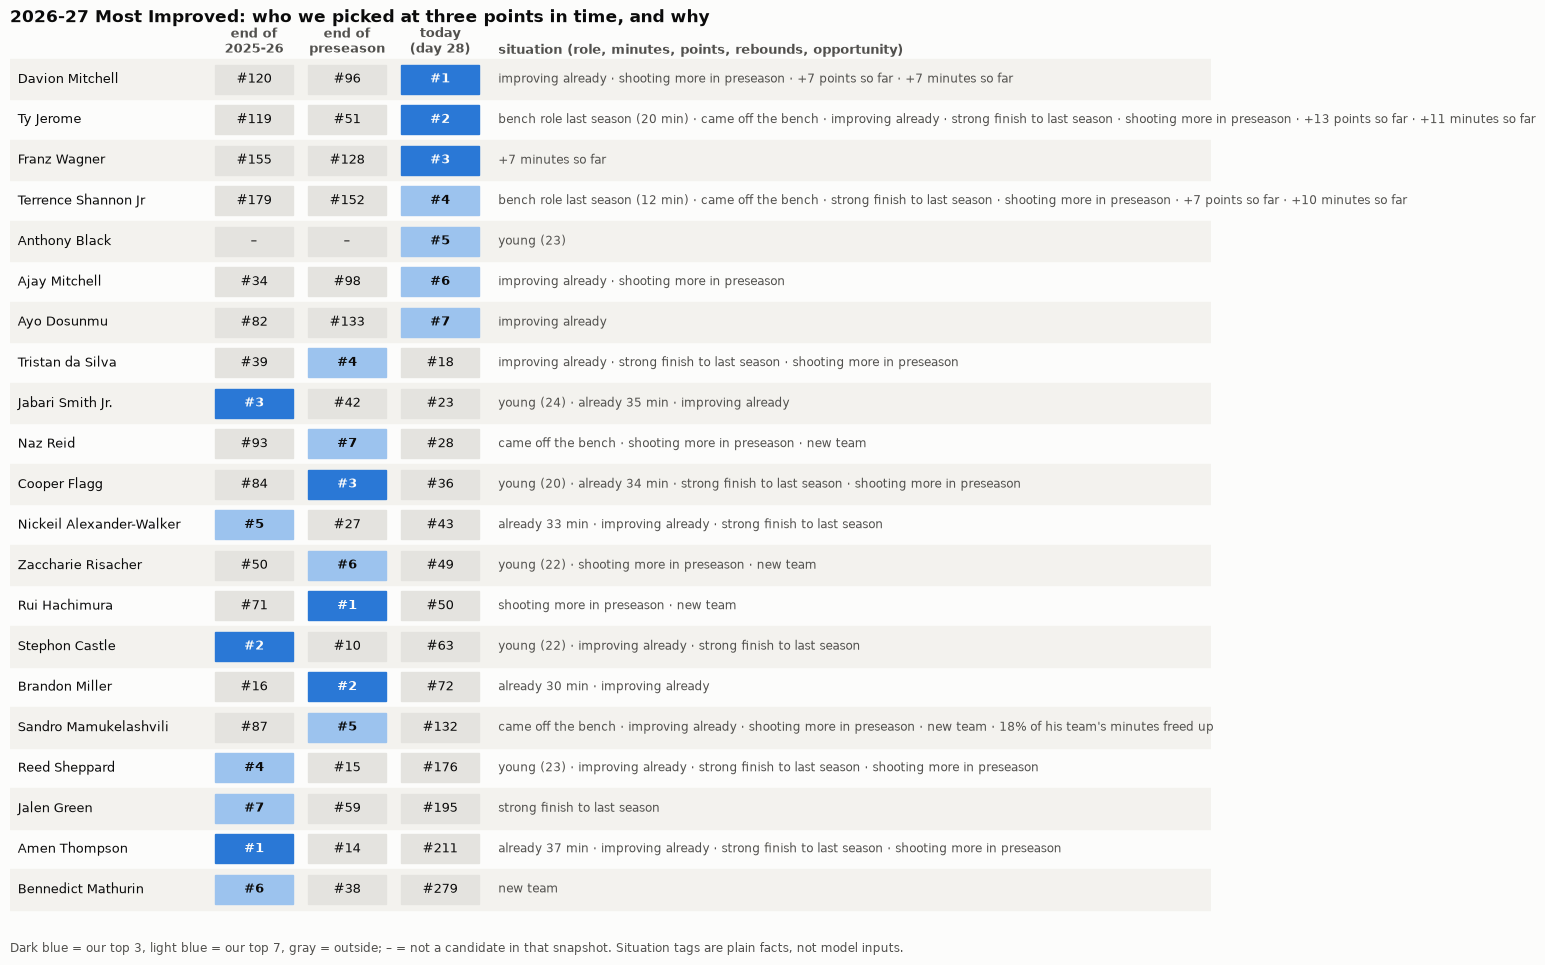

In [9]:
fig_rows = facts.sort_values(["rank: today"]).copy()
n = len(fig_rows)
fig, ax = plt.subplots(figsize=(15.5, 0.48 * n + 1.6))
ax.set_xlim(0, 15.5); ax.set_ylim(n, -1.2); ax.axis("off")
cols_x = {"end of 2025-26": 3.15, "end of preseason": 4.35, "today": 5.55}
for x, label in zip(cols_x.values(), ["end of\n2025-26", "end of\npreseason", f"today\n(day {DAY_NOW})"]):
    ax.text(x, -0.55, label, ha="center", va="bottom", fontsize=9, color=INK2, fontweight="bold")
ax.text(6.3, -0.55, "situation (role, minutes, points, rebounds, opportunity)", ha="left", va="bottom", fontsize=9, color=INK2, fontweight="bold")
for i, (name, r) in enumerate(fig_rows.iterrows()):
    if i % 2 == 0:
        ax.add_patch(plt.Rectangle((0, i - 0.5), 15.5, 1, color="#f3f2ee", zorder=0))
    ax.text(0.1, i, name, va="center", fontsize=9.5, color=INK)
    for k, x in cols_x.items():
        rk = r[f"rank: {k}"]
        top = pd.notna(rk) and rk <= 7
        ax.add_patch(plt.Rectangle((x - 0.5, i - 0.36), 1.0, 0.72, color=(BLUE if pd.notna(rk) and rk <= 3 else "#9cc3ee" if top else "#e4e3df"), zorder=1))
        ax.text(x, i, "–" if pd.isna(rk) else f"#{int(rk)}", ha="center", va="center", fontsize=9, zorder=2,
                color=SURFACE if pd.notna(rk) and rk <= 3 else INK, fontweight="bold" if top else "normal")
    ax.text(6.3, i, r["situation"], va="center", fontsize=8.3, color=INK2)
ax.set_title(f"{LIVE} Most Improved: who we picked at three points in time, and why", loc="left", fontsize=12, x=0)
ax.text(0, n + 0.3, "Dark blue = our top 3, light blue = our top 7, gray = outside; – = not a candidate in that snapshot. "
        "Situation tags are plain facts, not model inputs.", fontsize=8.5, color=INK2, va="top")
fig.savefig(FIG_DIR / "12_three_snapshots.png", dpi=150, bbox_inches="tight")

### B findings (17 November, day 28 after opening night)

**End of 2025-26: young players already playing big minutes and already improving.** Amen Thompson, Stephon Castle, Jabari Smith Jr., Reed Sheppard, Nickeil Alexander-Walker, Bennedict Mathurin and Jalen Green. This model has no information about the summer, so it can only extend last season's trend.

**End of preseason: the summer's moves reshape the list.** Rui Hachimura (Kawhi Leonard left the Clippers) goes to #1, then Brandon Miller (LaMelo Ball left Charlotte), Cooper Flagg (Anthony Davis left Dallas), Tristan da Silva, Sandro Mamukelashvili, Zaccharie Risacher and Naz Reid. This is the list in notebook 11.

**Today: a new list.** Davion Mitchell, today's leader, was 120th at the end of 2025-26 and 96th at the end of preseason. Ty Jerome was 119th and 51st, held back by his lost season; Franz Wagner was 155th and 128th; Terrence Shannon Jr was 179th and 152nd. Anthony Black is not on either earlier list, because he played no preseason games and both lists are drawn from players with preseason minutes.
- **Tristan da Silva is the closest of the earlier picks:** 4th before the season, 18th today. Cooper Flagg (3rd before the season) is 36th, held back by the established-star inputs (D42). Jabari Smith Jr. (3rd at the end of 2025-26) is 23rd.
- **Hachimura, #1 before the season, is 50th; Brandon Miller is 72nd.**
- The five-season backtest (notebook 4) says preseason lists catch the winner in about 3 seasons in 5. So "Mitchell has the best start" is the right reading, not "Mitchell will win".

**Reasons, by type**
- **Role:** several of today's risers came off the bench last season (Jerome, Shannon) or have moved into bigger roles (Wagner +7 minutes, Davion Mitchell +7). The earlier lists favoured players who already started and played 30+ minutes, or who inherit a departed star's role.
- **Minutes:** the movers have gained minutes (Jerome +11, Shannon +10, Wagner +7, Davion Mitchell +7), and points have come with them.
- **Points and rebounds:** the model leans on points and game score.
- **Opportunity:** the share of his team's 2025-26 minutes that left over the summer, minus the share brought in. It counts players on the team at the end of last season (only their minutes for that team), excludes the player's own minutes, and doesn't count players not yet seen in a game as gone. Tested as a preseason input, it adds nothing beyond the star flag, so it's shown as a fact only.

*Correction (30 October):* an earlier version showed opportunity as "minutes per game that left his team" (e.g. "62 min/game"). That was team minutes per game out of 240, not a player's minutes. It also counted players not yet seen as gone, gave traded players' whole season to their last team, and included the player's own minutes as an arrival. All four are fixed.

## C — The daily leaderboard, and how it has moved

One leaderboard for **every day of the season**, built as if we had run it that evening:
- **Day 0 = opening night.** Day *n* uses only games played up to *n* days after opening night.
- **The model for day *n*** is trained on past seasons cut at the same day *n*, so every day's chances are what we would have said at the time.
- **Days are saved once and never recomputed** (`data/processed/mip_race_daily_2026_27.parquet`). Each re-run adds only the new days. If the model settings change, the file is rebuilt from day 1.

The chart at the end is the "worm": each player's rank, day by day.

In [10]:
# DAILY_BOARD
DAILY_PATH = PROJECT_ROOT / "data" / "processed" / "mip_race_daily_2026_27.parquet"
SETTINGS = (f"features={EARLY}|l2={L2}|rules=1+ prior season, half of team games, previous winners included, "
            f"turning point on {LIVE_LEVEL}, chosen daily from {LIVE_TURN_CHOICES} (None = none), frozen at the All-Star break")

def board_for_day(day_index):
    """Full leaderboard after `day_index` days (0 = opening night), using only games up to that day."""
    c = race(day_index)
    k = turn_for_day(day_index)
    c = with_turn(c, LIVE_LEVEL, k)
    h, t = c[c["season"] != LIVE], c[c["season"] == LIVE].copy()
    t["chance"] = ChoiceModel(EARLY, L2).fit(h).predict_proba(t)
    t["turning_point"] = np.nan if k is None else float(k)
    t["rank"] = t["chance"].rank(ascending=False, method="first").astype(int)
    t["day"] = day_index                               # days after opening night (0 = opening night)
    t["date"] = live_games["game_date"].min() + pd.Timedelta(days=day_index)
    return t[["day", "date", "player_id", "player_name", "team", "games", "ppg", "base_ppg", "game_score", "base_game_score", "mpg", "base_mpg", "turning_point", "chance", "rank"]]

daily = pd.read_parquet(DAILY_PATH) if DAILY_PATH.exists() else pd.DataFrame()
if len(daily) and daily.loc[daily["date"] == live_games["game_date"].min(), "day"].eq(1).all():
    daily["day"] -= 1                                  # one-off relabel (13 November): the file counted opening night as day 1; nothing recomputed
    daily.to_parquet(DAILY_PATH, index=False)
if len(daily) and (daily["settings"].iloc[0] != SETTINGS):
    print("model settings changed: rebuilding from day 1"); daily = pd.DataFrame()
done = set(daily["day"]) if len(daily) else set()
new = [board_for_day(d).assign(settings=SETTINGS) for d in range(DAY_NOW + 1) if d not in done]
if new:
    daily = pd.concat([daily, *new], ignore_index=True).sort_values(["day", "rank"])
    daily.to_parquet(DAILY_PATH, index=False)
print(f"days on file: 0–{daily['day'].max()} after opening night (added {len(new)} today)")
print("turning point by day:", daily.groupby("day")["turning_point"].first().map(lambda v: "none" if pd.isna(v) else f"{v:g}").to_dict())

top7 = daily[daily["rank"] <= 7].pivot(index="rank", columns="day", values="player_name")
top7.columns = [f"day {d} ({daily.loc[daily['day'] == d, 'date'].iloc[0]:%d %b})" for d in top7.columns]
top7

days on file: 0–28 after opening night (added 6 today)
turning point by day: {0: '12.5', 1: 'none', 2: 'none', 3: 'none', 4: '14', 5: '14', 6: '14', 7: 'none', 8: '14', 9: '14', 10: '14', 11: '14', 12: '14', 13: '15.5', 14: '15.5', 15: '14', 16: '14', 17: '14', 18: '15.5', 19: '14', 20: '14', 21: '14', 22: '15.5', 23: '15.5', 24: '15.5', 25: '15.5', 26: '15.5', 27: '15.5', 28: '15.5'}


,day 0 (20 Oct),day 1 (21 Oct),day 2 (22 Oct),day 3 (23 Oct),day 4 (24 Oct),day 5 (25 Oct),day 6 (26 Oct),day 7 (27 Oct),day 8 (28 Oct),day 9 (29 Oct),...,day 19 (08 Nov),day 20 (09 Nov),day 21 (10 Nov),day 22 (11 Nov),day 23 (12 Nov),day 24 (13 Nov),day 25 (14 Nov),day 26 (15 Nov),day 27 (16 Nov),day 28 (17 Nov)
rank,,,,,,,,,,,,,,,,,,,,,
1,Jared McCain,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ja'Kobe Walter,...,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Franz Wagner,Davion Mitchell,Davion Mitchell,Davion Mitchell,Davion Mitchell
2,Dylan Harper,Jabari Smith Jr.,Yves Missi,Tyler Herro,Walker Kessler,Ja'Kobe Walter,Ja'Kobe Walter,Ja'Kobe Walter,Ja'Kobe Walter,Ty Jerome,...,Ajay Mitchell,Ajay Mitchell,Davion Mitchell,Davion Mitchell,Davion Mitchell,Davion Mitchell,Franz Wagner,Franz Wagner,Franz Wagner,Ty Jerome
3,Ausar Thompson,Yves Missi,Jabari Smith Jr.,Walker Kessler,Jaxson Hayes,Franz Wagner,Franz Wagner,Franz Wagner,Terrence Shannon Jr,Terrence Shannon Jr,...,Kyshawn George,Davion Mitchell,Anthony Black,Anthony Black,Anthony Black,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Franz Wagner
4,Julian Champagnie,Moussa Diabaté,Tyler Herro,Jaxson Hayes,Davion Mitchell,Davion Mitchell,Tyler Herro,Tyler Herro,Brandon Miller,Brandon Miller,...,Davion Mitchell,Brandin Podziemski,Franz Wagner,Franz Wagner,Franz Wagner,Ajay Mitchell,Ajay Mitchell,Anthony Black,Terrence Shannon Jr,Terrence Shannon Jr
5,Paul George,Tyler Herro,Moussa Diabaté,Ayo Dosunmu,Ja'Kobe Walter,Naz Reid,Zaccharie Risacher,Brandon Miller,Ajay Mitchell,Ajay Mitchell,...,Anthony Black,Kyshawn George,Ajay Mitchell,Ajay Mitchell,Brandin Podziemski,Anthony Black,Anthony Black,Ajay Mitchell,Anthony Black,Anthony Black
6,Andre Drummond,Naz Reid,Naz Reid,Naz Reid,Dyson Daniels,Jaxson Hayes,Brandon Miller,Terrence Shannon Jr,RJ Barrett,RJ Barrett,...,Ayo Dosunmu,Ayo Dosunmu,Brandin Podziemski,Brandin Podziemski,Ajay Mitchell,Ayo Dosunmu,Ayo Dosunmu,Ayo Dosunmu,Ajay Mitchell,Ajay Mitchell
7,Jordan Walsh,Dyson Daniels,Ja'Kobe Walter,Davion Mitchell,Ayo Dosunmu,Kyshawn George,Jaxson Hayes,Jaxson Hayes,Zaccharie Risacher,Zaccharie Risacher,...,Jabari Smith Jr.,Anthony Black,Kyshawn George,Kyshawn George,Ayo Dosunmu,Brandin Podziemski,Brandin Podziemski,Brandin Podziemski,Jalen Smith,Ayo Dosunmu


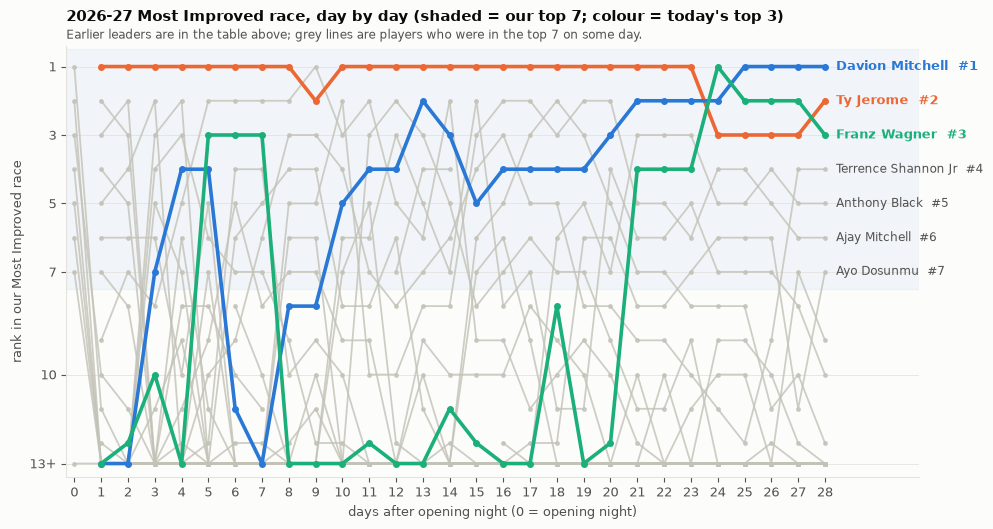

In [11]:
# worm chart: rank by day for everyone who has been in the top 7; the current top 3 in colour
ever = daily.loc[daily["rank"] <= 7, "player_id"].unique()
last_day = daily["day"].max()
now_top3 = daily[(daily["day"] == last_day)].nsmallest(3, "rank")["player_id"].tolist()
colours = dict(zip(now_top3, [BLUE, ORANGE, SERIES[2]]))
SHOW = 12                                     # ranks below this are drawn at the bottom edge
fig, ax = plt.subplots(figsize=(11, 5.6))
for pid in ever:
    d = daily[daily["player_id"] == pid].set_index("day")["rank"].reindex(range(0, last_day + 1))
    y = d.clip(upper=SHOW + 0.6)
    top = pid in colours
    ax.plot(y.index, y, color=colours.get(pid, MUTED), linewidth=2.6 if top else 1.3, alpha=1 if top else 0.8,
            marker="o", markersize=4 if top else 2.5, zorder=3 if top else 2)
    last = d.dropna()
    name = daily.loc[daily["player_id"] == pid, "player_name"].iloc[0]
    if top:
        ax.annotate(f"{name}  #{int(d.iloc[-1])}", (last_day, min(d.iloc[-1], SHOW + 0.6)), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=9.5, color=colours[pid], fontweight="bold")
    elif pd.notna(d.iloc[-1]) and d.iloc[-1] <= 7:   # the rest of today's top 7, named at the right edge
        ax.annotate(f"{name}  #{int(d.iloc[-1])}", (last_day, d.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK2)
ax.axhspan(0.5, 7.5, color=BLUE, alpha=0.05, zorder=0)
ax.set_ylim(SHOW + 1, 0.4); ax.set_yticks([1, 3, 5, 7, 10, SHOW + 0.6], ["1", "3", "5", "7", "10", f"{SHOW + 1}+"])
ax.set_xlim(-0.3, last_day + 3.5); ax.set_xticks(range(0, last_day + 1))
ax.set_xlabel("days after opening night (0 = opening night)"); ax.set_ylabel("rank in our Most Improved race")
ax.grid(axis="x", visible=False)
ax.set_title(f"{LIVE} Most Improved race, day by day (shaded = our top 7; colour = today's top 3)", loc="left", pad=18)
ax.text(0, 1.01, "Earlier leaders are in the table above; grey lines are players who were in the top 7 on some day.", transform=ax.transAxes, fontsize=8.5, color=INK2, va="bottom")
fig.savefig(FIG_DIR / "12_daily_worm.png", dpi=150, bbox_inches="tight")

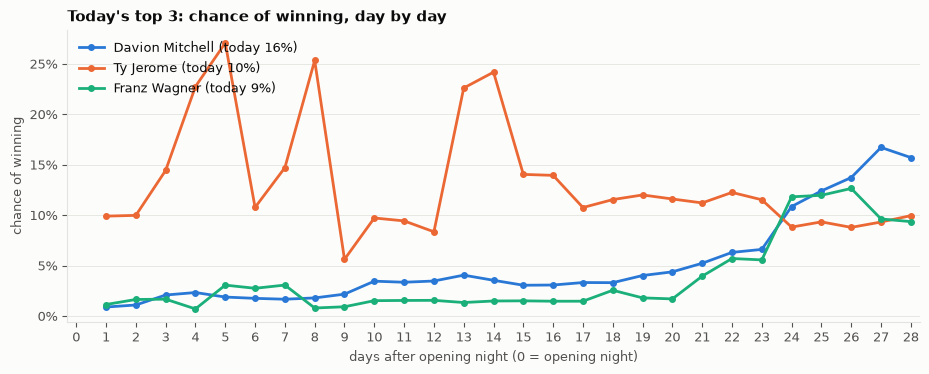

In [12]:
# the same story in chances: today's top 3 against the rest of the field
fig, ax = plt.subplots(figsize=(11, 3.8))
for pid in now_top3:
    d = daily[daily["player_id"] == pid].set_index("day")["chance"].reindex(range(0, last_day + 1))
    name = daily.loc[daily["player_id"] == pid, "player_name"].iloc[0]
    ax.plot(d.index, d, color=colours[pid], marker="o", markersize=4, label=f"{name} (today {d.iloc[-1]:.0%})")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xticks(range(0, last_day + 1)); ax.set_xlim(-0.3, last_day + 0.3)
ax.set_xlabel("days after opening night (0 = opening night)"); ax.set_ylabel("chance of winning")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
ax.set_title("Today's top 3: chance of winning, day by day", loc="left")
fig.savefig(FIG_DIR / "12_daily_chance.png", dpi=150, bbox_inches="tight")

### C findings (11 November, day 22 after opening night)

- **The daily file was rebuilt from day 1 on 12 November,** because the turning point moved to game score (D41) and the established-star inputs were added (D42); before that on 10 November for the lost-season input (D39) and on 9 November for the All-Star input (D38). Each day still uses only games up to that day, plus what was known on opening night: earlier All-Star selections, and whether last season was lost.
- **Opening night (day 0) had only two games,** so the first leaderboard is four teams' players.
- **Ty Jerome has led on 21 of the 22 days since his first game.** Only Ja'Kobe Walter (day 9, 29 October) interrupted him.
- **The turning point the data chooses has moved more since D42** (none, 14 or 15.5 on different days). It is frozen at the All-Star break (D32).
- **#2 has changed hands often:** Ajay Mitchell and Kyshawn George have held it most recently, and Davion Mitchell holds it now.
- **Chances move more than ranks.** Each day's model is trained separately on past seasons cut at that day, and with only a few games per player one quiet night moves a lot. **Read the ranks for the trend and the chances for the size of the lead.**

**How to keep it going:** run `./scripts/update_mip_race.sh` (or this notebook, top to bottom) whenever you like. It adds every day since the last run and redraws both charts; days already on file are never recomputed unless the model settings change.